# Parsimonious Models and Feature Selection

### Methodology & Deployment Simulation

To prevent target leakage and ensure rigorous generalisation, parsimonious model construction strictly adheres to the following principles:

1. **Development-Only Feature Selection:** Feature ranking and selection are performed exclusively on the training and validation splits using a baseline logistic regression ranking model.
2. **Held-Out Test Evaluation:** Selected feature sets (`top_5`, `top_10`, `top_20`, `top_30`, and `full`) are refitted on development data and evaluated independently on the untouched temporal test set.

In [16]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Setup, Data Ingestion, and Splitting

We load the configuration, ingest the processed dataset, map the target variable, and isolate development splits from the held-out temporal test set.

In [4]:
from pathlib import Path
import yaml
import pandas as pd
from IPython.display import display

from icare_risk.data.audit import load_admission_file
from icare_risk.data.feature_sets import resolve_feature_set
from icare_risk.models.training import fit_model, encode_binary_target
from icare_risk.models.prediction import predict_probability
from icare_risk.explainability.feature_selection import rank_pipeline_features, feature_set_table
from icare_risk.evaluation.metrics import compute_metrics

# Load configuration
CONFIG_PATH = Path('../src/icare_risk/config/icare/analysis.yaml')
with CONFIG_PATH.open() as f:
    config = yaml.safe_load(f)
print(f"Using configuration: {CONFIG_PATH}")


Using configuration: ../src/icare_risk/config/icare/analysis.yaml


In [5]:
target = config["columns"]["target"]
target_mapping = config.get("target_mapping")

df = load_admission_file(config["outputs"]["processed_dataset"])
required = [target, "split"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")

df["_target_numeric"] = encode_binary_target(
    df[target],
    positive_values=target_mapping.get("positive_values"),
    negative_values=target_mapping.get("negative_values"),
)

n_before = len(df)
df = df.loc[df["_target_numeric"].notna()].copy()
print(f"Excluded unresolved outcomes: {n_before - len(df):,}")

development = df.loc[df["split"].isin(["train", "validation"])].copy()
test = df.loc[df["split"].eq("test")].copy()
print(f"Development rows: {len(development):,}; test rows: {len(test):,}")
print(f"Development events: {int(development['_target_numeric'].sum()):,}")
print(f"Test events: {int(test['_target_numeric'].sum()):,}")


Excluded unresolved outcomes: 0
Development rows: 7,517; test rows: 2,483
Development events: 1,465
Test events: 493


## 2. Feature Ranking & Subset Generation

Using the development split, we fit a baseline ranking model to score all available baseline features by absolute coefficient magnitude, building parsimonious feature subsets of varying sizes.

In [6]:
feature_cfg = config["feature_sets"].get("all_available_baseline")
if feature_cfg is None:
    raise KeyError("analysis.yaml must define feature_sets.all_available_baseline")

features = resolve_feature_set(
    df, feature_cfg,
    exclude_columns=[target, "split", "_target_numeric"],
)
print(f"Resolved {len(features)} baseline features")
display(pd.DataFrame({"feature": features}))


Resolved 170 baseline features


,feature
0,AGE_AT_ADMISSION
1,MAIN_SPECIALTY_CODE
2,MAIN_SPECIALTY_CODE_DESC
3,INDEX_OF_MULTIPLE_DEPRIVATION_DECILE
4,index_admission
...,...
165,days_since_last_discharge
166,ETHNICITY
167,ETHNICITY_DES
168,GENDER


In [7]:
ranking_cfg = config.get("explainability", {})
ranking_model = fit_model(
    development,
    features,
    target,
    model_type=ranking_cfg.get("ranking_model_type", "logistic_regression"),
    params=ranking_cfg.get("ranking_model_params", {"C": 1.0}),
    target_mapping=target_mapping,
)
ranking = rank_pipeline_features(ranking_model, features)
display(ranking.head(30))

sizes = tuple(ranking_cfg.get("parsimonious_feature_sizes", [5, 10, 20, 30]))
feature_sets = feature_set_table(ranking, sizes=sizes)
print("Feature sets:", {name: len(cols) for name, cols in feature_sets.items()})


/usr/local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['kim_hx_urinary_catheter_dslast' 'kim_hx_urinary_catheter_dsfirst'
 'tumbarello_hx_urinary_catheter_dslast'
 'tumbarello_hx_urinary_catheter_dsfirst'
 'gavaghan_hx_urinary_catheter_dslast'
 'gavaghan_hx_urinary_catheter_dsfirst' 'days_since_last_discharge']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


,rank,feature,importance
0,1,charlson_hx_lymphoma,0.448425
1,2,charlson_hx_lymphoma_cnt,0.448425
2,3,charlson_hx_diabetes_comp_cnt,0.394936
3,4,charlson_hx_diabetes_comp,0.394936
4,5,charlson_hx_dementia_cnt,0.391457
5,6,charlson_hx_dementia,0.391457
6,7,charlson_hx_rheum_cnt,0.344893
7,8,charlson_hx_rheum,0.344893
8,9,charlson_hx_aids_cnt,0.297544
9,10,charlson_hx_aids,0.297544


Feature sets: {'full': 156, 'top_5': 5, 'top_10': 10, 'top_20': 20, 'top_30': 30}


## 3. Training Parsimonious Models & Disk Export

We refit reduced logistic regression models for each feature subset, evaluate them on the held-out test set, and persist all resulting feature rankings and performance metrics to disk as CSV files.

In [14]:
threshold = float(config["analysis"]["evaluation_threshold"])
rows = []

for feature_set_name, selected_features in feature_sets.items():
    print(f"Fitting parsimonious model: {feature_set_name} ({len(selected_features)} features)...")
    fitted = fit_model(
        development, selected_features, target,
        model_type="logistic_regression",
        params=ranking_cfg.get("ranking_model_params", {"C": 1.0}),
        target_mapping=target_mapping,
    )
    probability = predict_probability(fitted, test, selected_features)
    metrics = compute_metrics(
        test[target],
        probability,
        threshold=threshold,
        target_mapping=target_mapping
    )
    rows.append({
        "model": f"lr_{feature_set_name}",
        "n_features": len(selected_features),
        **metrics,
    })

parsimonious_results = (
    pd.DataFrame(rows)
    .sort_values(["auroc", "auprc"], ascending=False, na_position="last")
    .reset_index(drop=True)
)
display(parsimonious_results)


Fitting parsimonious model: full (156 features)...
Fitting parsimonious model: top_5 (5 features)...
Fitting parsimonious model: top_10 (10 features)...
Fitting parsimonious model: top_20 (20 features)...
Fitting parsimonious model: top_30 (30 features)...


,model,n_features,n,n_events,event_rate,auroc,auprc,brier_score,threshold,tp,tn,fp,fn,sensitivity,specificity,ppv,npv,accuracy,balanced_accuracy,f1
0,lr_top_5,5,2483,493,0.19855,0.504065,0.200068,0.250020,0.5,8,1967,23,485,0.016227,0.988442,0.258065,0.802202,0.795409,0.502335,0.030534
1,lr_top_10,10,2483,493,0.19855,0.503782,0.199955,0.249886,0.5,10,1963,27,483,0.020284,0.986432,0.270270,0.802535,0.794603,0.503358,0.037736
2,lr_top_30,30,2483,493,0.19855,0.502279,0.205371,0.249454,0.5,77,1705,285,416,0.156187,0.856784,0.212707,0.803866,0.717680,0.506485,0.180117
3,lr_top_20,20,2483,493,0.19855,0.500678,0.203907,0.250134,0.5,77,1707,283,416,0.156187,0.857789,0.213889,0.804051,0.718486,0.506988,0.180539
4,lr_full,156,2483,493,0.19855,0.473575,0.188030,0.253459,0.5,200,1108,882,293,0.405680,0.556784,0.184843,0.790864,0.526782,0.481232,0.253968


In [15]:
output_dir = Path(config["outputs"]["feature_importance_directory"])
output_dir.mkdir(parents=True, exist_ok=True)

ranking.to_csv(output_dir / "development_feature_ranking.csv", index=False)
parsimonious_results.to_csv(
    output_dir / "parsimonious_model_results.csv",
    index=False,
)

for name, selected in feature_sets.items():
    pd.DataFrame({"feature": selected}).to_csv(
        output_dir / f"{name}_features.csv",
        index=False,
    )

print(f"Successfully saved all parsimonious artifacts to: {output_dir.resolve()}")

Successfully saved all parsimonious artifacts to: /app/notebooks/results/feature_importance


### Parsimonious Model Performance & Visualization

Below, we load the saved `.csv` artifacts back from disk, render a formatted summary table comparing discrimination metrics across feature subset sizes, and plot the $ROC-AUC$ trend as a function of model complexity.

In [16]:
# Load metrics back from disk storage
loaded_results = pd.read_csv(output_dir / "parsimonious_model_results.csv")
print(loaded_results)

       model  n_features     n  n_events  event_rate     auroc     auprc  \
0   lr_top_5           5  2483       493     0.19855  0.504065  0.200068   
1  lr_top_10          10  2483       493     0.19855  0.503782  0.199955   
2  lr_top_30          30  2483       493     0.19855  0.502279  0.205371   
3  lr_top_20          20  2483       493     0.19855  0.500678  0.203907   
4    lr_full         156  2483       493     0.19855  0.473575  0.188030   

   brier_score  threshold   tp    tn   fp   fn  sensitivity  specificity  \
0     0.250020        0.5    8  1967   23  485     0.016227     0.988442   
1     0.249886        0.5   10  1963   27  483     0.020284     0.986432   
2     0.249454        0.5   77  1705  285  416     0.156187     0.856784   
3     0.250134        0.5   77  1707  283  416     0.156187     0.857789   
4     0.253459        0.5  200  1108  882  293     0.405680     0.556784   

        ppv       npv  accuracy  balanced_accuracy        f1  
0  0.258065  0.802202  

,model,n_features,auroc,auprc,brier_score,sensitivity,specificity
0,lr_top_5,5,0.504,0.200,0.250,0.016,0.988
1,lr_top_10,10,0.504,0.200,0.250,0.020,0.986
2,lr_top_30,30,0.502,0.205,0.249,0.156,0.857
3,lr_top_20,20,0.501,0.204,0.250,0.156,0.858
4,lr_full,156,0.474,0.188,0.253,0.406,0.557


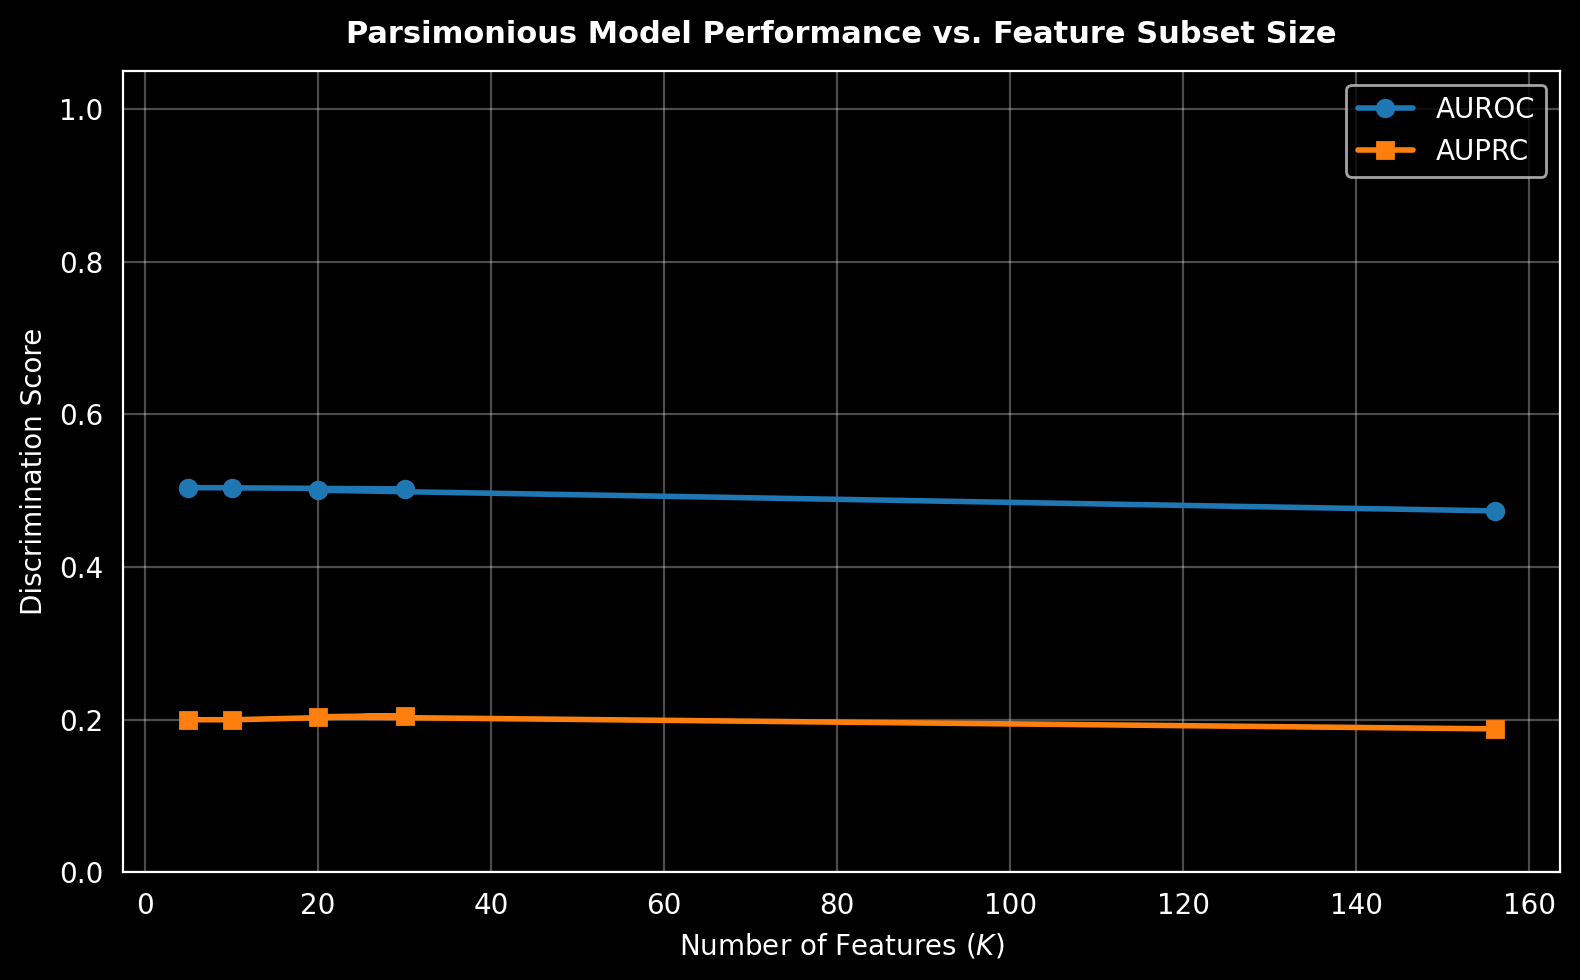

Successfully loaded saved CSV artifacts and rendered performance visualizations.


In [17]:
import matplotlib.pyplot as plt

# Load metrics back from disk storage
loaded_results = pd.read_csv(output_dir / "parsimonious_model_results.csv")

# Display styled summary table
styled_table = loaded_results[['model', 'n_features', 'auroc', 'auprc', 'brier_score', 'sensitivity', 'specificity']].style.format({
    'auroc': '{:.3f}',
    'auprc': '{:.3f}',
    'brier_score': '{:.3f}',
    'sensitivity': '{:.3f}',
    'specificity': '{:.3f}'
}).background_gradient(subset=['auroc', 'auprc'], cmap='Greens')

display(styled_table)

# Generate performance vs. number of features plot
fig, ax = plt.subplots(figsize=(8, 5), dpi=200)
ax.plot(loaded_results['n_features'], loaded_results['auroc'], marker='o', color='#1f77b4', linewidth=2, label='AUROC')
ax.plot(loaded_results['n_features'], loaded_results['auprc'], marker='s', color='#ff7f0e', linewidth=2, label='AUPRC')

ax.set_title("Parsimonious Model Performance vs. Feature Subset Size", fontsize=11, fontweight="bold", pad=10)
ax.set_xlabel("Number of Features ($K$)", fontsize=10)
ax.set_ylabel("Discrimination Score", fontsize=10)
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)
ax.legend(frameon=True)

plt.tight_layout()
plt.show()

print("Successfully loaded saved CSV artifacts and rendered performance visualizations.")